> **언어 전환 & 바로가기**: **🇰🇷 한국어 (현재 폴더: `notebooks/ko/`)** · [🇺🇸 English (`notebooks/en/stage4_agent_and_mcp_execution_en.ipynb`)](../en/stage4_agent_and_mcp_execution_en.ipynb) ｜ [스타터 README](../../README.md) ｜ [노트북 전체 인덱스 (README)](../README.md) ｜ [스타터 데모 열기](https://agentic-ontology-starter-115847445822.asia-northeast3.run.app/)
>
> **전체 라이프사이클 네비게이션**: [0. 전체 흐름 개요](./stage0_overview_walkthrough_ko.ipynb) → [Stage 1 · 준비·분석](./stage1_asset_and_cq_ko.ipynb) → [Stage 2 · 파싱·통합](./stage2_wiki_and_semantic_graph_ko.ipynb) → [Stage 3 · 그래프 구축](./stage3_property_graph_bigquery_spanner_ko.ipynb) → **[▶ Stage 4 · 에이전트·답변](./stage4_agent_and_mcp_execution_ko.ipynb)** → [Stage 5 · 리니지·검증](./stage5_lineage_and_evaluation_ko.ipynb)

---

# Stage 4. [에이전트 구축 & 답변] 리소스 직결 도메인 비즈니스 도구(3종) · 슬롯 검증 & 2-Pass AI FDE(`Gate G2-W`) 답변 생성
## Step 4.1 도메인 비즈니스 도구 3종 카탈로그(`get_tool_catalog`) 점검 · Step 4.2 결정론적 산식 시뮬레이션 및 `Gate G2-W` 답변 생성

Stage 4는 방법론의 **Phase 6(에이전트 구축)**과 **Phase 7(답변 생성)**을 구현합니다. 스타터팩 v2.2.0에서는 무거운 내부 온톨로지 빌더 도구를 제외하고 **Ready-to-Use GCP 리소스에 직결된 도메인 비즈니스 도구 3종(`mcp_lookup_customer_profile`, `mcp_calculate_penalty_rule`, `mcp_query_graph_and_wiki`)**만 깔끔하게 노출합니다. LLM이 위약금이나 지원금을 암산하거나 존재하지 않는 요금제를 환각하지 않도록, **(1) BigQuery 실시간 카탈로그 기반 슬롯 검증(`resolve_params`)**, **(2) 결정론적 SQL 및 바인딩 변수 기반 ISO GQL을 양대 엔진(`engine='bigquery'` 기본값 및 `engine='spanner'`)에서 실행하는 도메인 비즈니스 도구(`DomainMcpServer`)**, **(3) `Gate G2-W` 런타임 감사를 수행하는 2-Pass Gemini(`gemini-4-argon`) 추론 엔진(`AiFdeAgentEngine`)**을 구축하고 정상 질의(`GROUNDED`)와 경계 질의(`INSUFFICIENT_PARAMETERS`, `MATCH_NOT_FOUND`)에 대한 답변을 생성합니다.

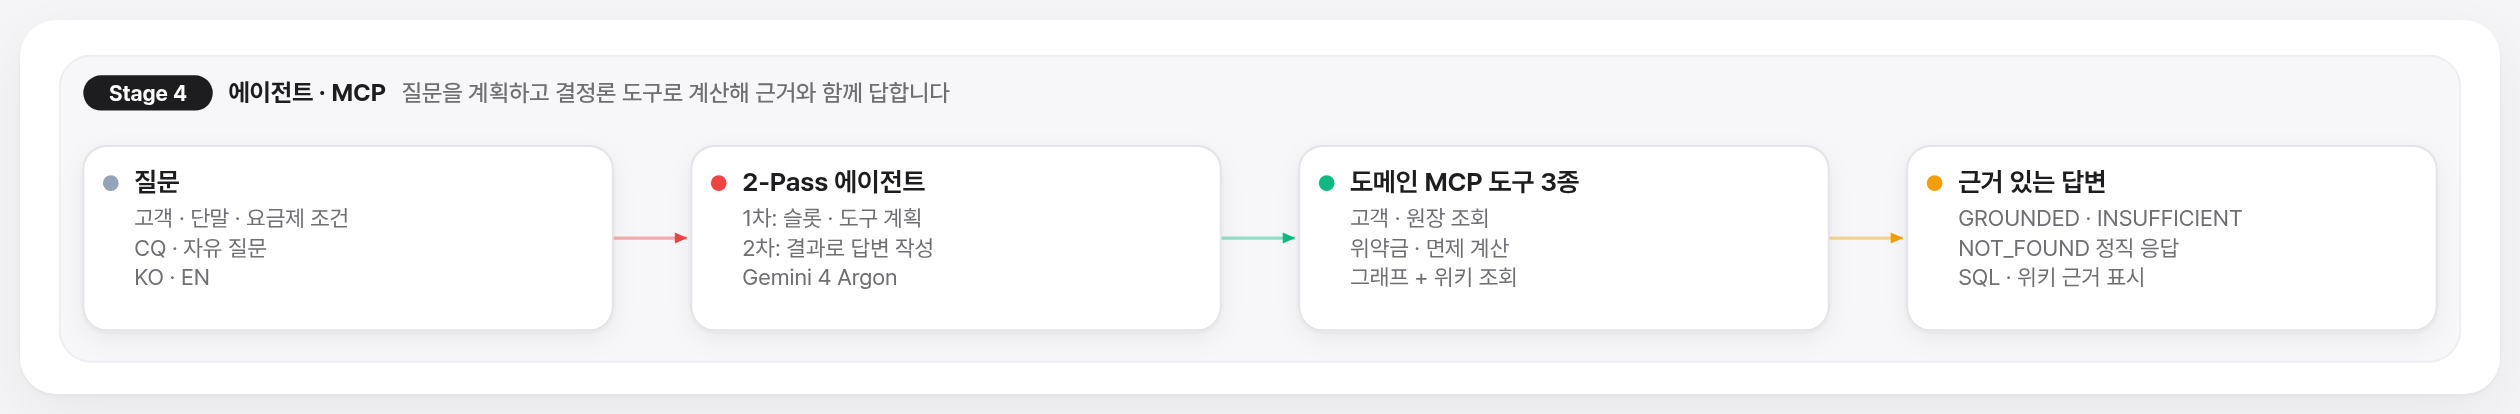


In [ ]:
%load_ext bigframes
import sys
from pathlib import Path
for _p in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    if (_p / "nb_helpers.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
from src.agent.reasoning_engine import AiFdeAgentEngine
H.setup("ko")
server = DomainMcpServer()
agent = AiFdeAgentEngine()


### 1. [Phase 6a: 리소스 직결 도메인 비즈니스 도구 3종 및 에이전트 구축] 코드 노출 경계 · 도메인 도구 3종 카탈로그 · `stage4_resource_check`


In [ ]:
H.draw_agent_architecture()
manifest = server.get_resource_manifest()
H.show(pd.DataFrame(manifest["code_exposure_boundary"]["exposed_starter_layer"])[["file", "category", "role_ko" if H.LANG == "ko" else "role_en"]])
H.show(pd.DataFrame(server.get_tool_catalog()), ["name", "stage", "category", "steps", "spec_source", "description" if H.LANG == "ko" else "description_en"])
res_s4 = server.execute_tool("stage4_resource_check", {"steps": ["step_4_1", "step_4_2"]})
H.show_tool(res_s4, "active_rules")


### 2. [Phase 6b: 카탈로그 기반 슬롯 파싱 검증 (`resolve_params`)] 자연어 질문에서 안전하게 파라미터를 추출하고 미등록 엔티티를 차단하는 과정


In [ ]:
sample_queries = [
    "CUST_DEMO_001 고객이 개통 120일 시점에 5G Light(37,000원)로 하향 변경하면 위약금이 얼마인가요?",
    "AlphaPhone 16 Pro 256GB 단말기를 5G Signature 115 요금제로 개통할 때 지원금과 실구매가는?",
    "CUST_NOT_EXIST_999 고객이 QuantumFold 99 단말기로 99,000원 요금제 변경 시 위약금은?",
    "방금 개통했는데 37,000원 요금제로 내리면 위약금이 얼마인가요?",
]
slot_rows = []
for q in sample_queries:
    resolved = server.resolve_params({"query": q})
    slot_rows.append({"query": q, **{k: v for k, v in resolved.items()}})
H.show(pd.DataFrame(slot_rows))


### 3. [Phase 6c: 런타임 도메인 MCP 3종 직접 호출 및 GQL 문장/변수 확인] 고객 프로필 · 위약금/24개월 TCO 산식 · 그래프/위키 탐색(`executed_gql`) 및 180일 위약금 곡선


In [ ]:
r_prof = server.execute_tool("mcp_lookup_customer_profile", {"customer_id": "CUST_DEMO_001"})
H.show_tool(r_prof, "matched_rows", ["customer_id", "device_name", "plan_name", "monthly_fee_krw", "factory_price_krw", "total_subsidy_krw", "net_installment_principal_krw", "grounded_chunk_id"])

r_pen = server.execute_tool("mcp_calculate_penalty_rule", {"customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120})
H.show_tool(r_pen, "calculations", ["customer_id", "plan_name", "target_plan_name", "elapsed_days", "penalty_status", "penalty_krw", "public_subsidy_24m_tco_krw", "selective_24m_tco_krw", "tco_recommendation", "grounded_chunk_id"])

r_gql = server.execute_tool("mcp_query_graph_and_wiki", {"customer_id": "CUST_DEMO_001"})
H.show_tool(r_gql, "matched_graph_paths", ["customer_id", "device_name", "plan_name", "rule_id", "relation_label_ko", "source_chunk_id", "anchor"])

df_curve = H.penalty_curve(server, "CUST_DEMO_001", 37000, [30, 60, 90, 120, 150, 179, 180, 200])
H.show(df_curve)
H.line(df_curve, "elapsed_days", "penalty_krw",
       "CUST_DEMO_001 경과일(30~200일)별 차액정산 위약금 시뮬레이션 곡선 (180일 면제 경계)",
       vline=180, vline_label="180d threshold")


In [ ]:
H.md("#### MCP 호출별 BigQuery 리소스 (`bq_jobs`: job_id · rows · elapsed_ms)")
H.show(pd.DataFrame([{"tool": r["tool"], "job_id": j["job_id"], "engine": j["engine"], "status": j["status"], "rows": j["rows"], "elapsed_ms": j["elapsed_ms"]}
                     for r in (r_prof, r_pen, r_gql) for j in r.get("bq_jobs", [])]))


### 4. [Phase 6d: 양대 그래프 엔진 도메인 도구 런타임 비교 (`engine="bigquery"` vs `engine="spanner"`)] Cloud Spanner Graph 직접 실행 및 결과 정합성·지연시간 대조


In [ ]:
df_mcp_eng = H.compare_mcp_engines(server)
H.show(df_mcp_eng)
H.grouped_bar(df_mcp_eng, "mcp_tool", ["bigquery_ms", "spanner_ms"],
              "런타임 도메인 MCP 도구 3종 — BigQuery(기본값) vs Cloud Spanner(100 PU) 실행 시간 비교 (ms)",
              fmt="{:,.1f}", ylabel="Latency (ms)")


### 5. [Phase 7: 2-Pass 에이전트 End-to-End 답변 생성] Golden CQ(`GROUNDED`) 및 경계 조건(`INSUFFICIENT_PARAMETERS`, `MATCH_NOT_FOUND`) 4단계 트레이스


In [ ]:
prompts = [
    ("CQ-01 (Subsidy & Net Price)", "AlphaPhone 16 Pro 256GB 단말기를 5G Signature 115 요금제로 개통할 때 공시지원금, 유통망 추가지원금 상한, 총 지원금과 실구매가는 얼마인가요?"),
    ("CQ-02 (120d Prorated Penalty)", "CUST_DEMO_001 고객이 개통 후 120일 시점에 월 37,000원 요금제(5G Lite 37)로 하향 변경하면 차액정산 위약금은 얼마인가요?"),
    ("CQ-03 (Welfare Exemption)", "국가유공자 복지감면 등록 고객인 CUST_DEMO_002가 개통 95일 만에 하위 요금제로 변경할 때 위약금이 면제되나요?"),
    ("BC-PARAM (Missing Customer/Device)", "방금 개통한 고객인데 지금 5G Lite 37 요금제로 내리면 위약금이 얼마인가요?"),
    ("BC-NOTFOUND (Unknown Entity)", "CUST_NOT_EXIST_999 고객이 QuantumFold 99 단말기로 요금제를 변경할 때 위약금을 계산해 주세요."),
]
runs = []
for qid, q in prompts:
    res = agent.execute_cycle(q)
    H.show_agent(res, title=qid)
    runs.append({**H.agent_row(res, qid.split()[0]), "prompt_tokens": res["llm_telemetry"]["prompt_tokens"],
                 "completion_tokens": res["llm_telemetry"]["candidates_tokens"]})
df_runs = pd.DataFrame(runs)
H.show(df_runs)
H.grouped_bar(df_runs, "id", ["llm_ms", "bq_ms"],
              "질의 시나리오별 Gemini 2-Pass 추론 시간 vs BigQuery SQL/GQL 실행 시간 (ms)")


### 6. Wiki Agent와 BQG Agent의 차이 및 사용량 보고

방법론은 두 에이전트를 근거를 가져오는 곳으로 구분한다.

| 구분 | Wiki Agent (방법론) | BQG Agent (방법론) |
| :--- | :--- | :--- |
| 근거 | GCS의 온톨로지 위키 파일 | BigQuery Property Graph |
| 절차 | GCS 위키 목차 읽기 → Flash가 엔티티·개념 파일 선택 → 선택한 파일(+관계 1단계) 읽기 → Flash가 파일 내용만으로 답변 | 슬롯 추출 → Property Graph에 파라미터 GQL 조회 → 코드로 계산 → 답변 |
| BigQuery·그래프 | 사용하지 않음 | 사용 |
| 사용량 보고 | 호출별 토큰(Vertex `usageMetadata`: 입력·출력·thinking), 단계별 지연시간 | 같은 항목 + 쿼리별 BigQuery job ID, 행 수, 소요 ms |

Wiki Agent를 따로 두는 이유는 물리 그래프 없이 Stage 2 산출물만으로 규정·산식 CQ에 답할 수 있는지 확인하기 위해서다.

**스타터 구현 (방법론과 다름)**
- 스타터에는 GCS Wiki Agent가 없다. GCS 온톨로지는 `gs://seanjung-poc-starter-ontology/ontology/{entities.md, concepts.md, rules.md, summary.md, ontology.jsonld}`이며, 엔티티별 파일이 아니라 집계 파일이다.
- Lite 트랙(`src/agent/reasoning_engine.py` `_lite_cycle`): `tb_doc_chunks` 전체 행을 Gemini 컨텍스트에 넣고 청크 ID 인용을 검사한다. BigQuery 조회 1회, 그래프는 쓰지 않는다.
- Standard/Full 트랙(이 노트북): `AiFdeAgentEngine`이 MCP 도구를 호출하고, 도구는 실제 BigQuery/Spanner 쿼리를 실행한다. 각 결과에 `bq_jobs`(job_id, rows, elapsed_ms, status, sql)와 `executed_sql`이 담긴다. bytes processed와 cache hit는 스타터 기록에 없다.
- 토큰: `llm_telemetry.prompt_tokens`/`candidates_tokens`(Vertex `usageMetadata`의 `promptTokenCount`/`candidatesTokenCount`, 분해·합성 호출 합계). thinking 토큰은 스타터가 기록하지 않는다.

**위 실행 결과에서 확인할 곳**: 섹션 3의 MCP 호출별 표(job ID, rows, elapsed ms), 섹션 5의 `df_runs`(prompt/completion 토큰, BigQuery job 수, LLM ms와 BigQuery ms).


### Q&A
- **Q.** AI FDE 에이전트는 위약금 계산 오류나 미등록 단말기/고객 환각을 어떻게 방지하며, 양대 그래프 엔진(`bigquery` / `spanner`)을 어떻게 전환하나요?
  - **A.** `resolve_params()`가 실시간 카탈로그(`get_live_catalog()`)와 대조하여 미등록 단말·요금제·고객 ID를 즉시 필터링하고, 모든 금액 계산과 그래프 탐색은 도메인 비즈니스 도구 3종(`mcp_lookup_customer_profile`, `mcp_calculate_penalty_rule`, `mcp_query_graph_and_wiki`)에서 `engine='bigquery'`(기본값) 또는 `engine='spanner'`를 지정해 결정론적 SQL/GQL로만 수행하며, 필수 정보 누락 시 `INSUFFICIENT_PARAMETERS`, 조건 불일치 시 `MATCH_NOT_FOUND` 상태를 반환합니다.

### Data Analysis Key Findings
- `CUST_DEMO_001` 경과일 시뮬레이션(30~200일) 결과, 위약금은 30일차 `250,000원`에서 120일차 `100,000원`, 179일차 `1,667원`으로 선형 감소하며 180일 도래 즉시 `0원`(`EXEMPT_RETENTION_COMPLETED`)으로 전환됩니다.
- 런타임 도메인 MCP 3종(`mcp_lookup_customer_profile`, `mcp_calculate_penalty_rule`, `mcp_query_graph_and_wiki`)을 `engine='bigquery'`(기본값)와 `engine='spanner'`(`100 PU`) 양쪽에서 실행한 결과 동일한 반환 행 수(`result_parity=True`)와 SHA-256 앵커 정합성을 확인했습니다.
- Golden CQ(`CQ-01`~`CQ-03`)는 모두 `GROUNDED` 상태와 함께 정확한 금액(`575,000원`, `100,000원`, `0원`) 및 SHA-256 청크 앵커·BigQuery Job ID를 인용하여 답변했고, `BC-PARAM`과 `BC-NOTFOUND`는 수치 환각 없이 차단되었습니다.

### Insights or Next Steps
- 마지막 단계인 `Stage 5 (리니지·검증)` 노트북으로 이동하여 원천 파일부터 CQ 답변까지의 엔드투엔드 데이터 리니지 그래프와 Golden CQ 5종 / Boundary 50회 반복 벤치마크 배포 게이트를 검증하세요.

---
> **다음 학습 이동 (Navigation)**: [⬅️ Stage 3 · 그래프 구축](./stage3_property_graph_bigquery_spanner_ko.ipynb) ｜ [🏠 0. 전체 흐름 초기 화면](./stage0_overview_walkthrough_ko.ipynb) ｜ [➡️ Stage 5 · 리니지·검증](./stage5_lineage_and_evaluation_ko.ipynb) ｜ [🌐 English Version](../en/stage4_agent_and_mcp_execution_en.ipynb) ｜ [📖 방법론 문서](../../methodology/ko/04_stage4_agent_and_mcp_ko.md)
